# Quick Start: Iterating over splits of gift-eval datasets
First lets check the names of all the datasets in the `gift-eval` directory.

Make sure you download the gift-eval benchmark and set the `GIFT-EVAL` environment variable correctly before running this notebook.



In [108]:
%matplotlib inline
import os
import math
from numpy import linalg as LA
from dotenv import load_dotenv
from pathlib import Path

import numpy as np
import sys

sys.path.append(str(Path.cwd().parent))

from gift_eval.data import Dataset
from src import KMD_lib
import importlib
importlib.reload(KMD_lib)


# Load environment variables
load_dotenv()

os.environ["GIFT_EVAL"] = "/Users/jonghyeonlee/KMD_TS/GiftEval_data"

# Get the GIFT_EVAL path from environment variables
gift_eval_path = os.getenv("GIFT_EVAL")

if gift_eval_path:
    # Convert to Path object for easier manipulation
    gift_eval_path = Path(gift_eval_path)

    # Get all subdirectories (dataset names) in the GIFT_EVAL path
    dataset_names = []
    for dataset_dir in gift_eval_path.iterdir():
        if dataset_dir.name.startswith("."):
            continue
        if dataset_dir.is_dir():
            freq_dirs = [d for d in dataset_dir.iterdir() if d.is_dir()]
            if freq_dirs:
                for freq_dir in freq_dirs:
                    dataset_names.append(f"{dataset_dir.name}/{freq_dir.name}")
            else:
                dataset_names.append(dataset_dir.name)

    print("Available datasets in GIFT_EVAL:")
    for name in sorted(dataset_names):
        print(f"- {name}")
else:
    print(
        "GIFT_EVAL path not found in environment variables. Please check your .env file."
    )

Available datasets in GIFT_EVAL:
- LOOP_SEATTLE/5T
- LOOP_SEATTLE/D
- LOOP_SEATTLE/H
- M_DENSE/D
- M_DENSE/H
- SZ_TAXI/15T
- SZ_TAXI/H
- bitbrains_fast_storage/5T
- bitbrains_fast_storage/H
- bitbrains_rnd/5T
- bitbrains_rnd/H
- bizitobs_application
- bizitobs_l2c/5T
- bizitobs_l2c/H
- bizitobs_service
- car_parts_with_missing
- covid_deaths
- electricity/15T
- electricity/D
- electricity/H
- electricity/W
- ett1/15T
- ett1/D
- ett1/H
- ett1/W
- ett2/15T
- ett2/D
- ett2/H
- ett2/W
- hierarchical_sales/D
- hierarchical_sales/W
- hospital
- jena_weather/10T
- jena_weather/D
- jena_weather/H
- kdd_cup_2018_with_missing/D
- kdd_cup_2018_with_missing/H
- m4_daily
- m4_hourly
- m4_monthly
- m4_quarterly
- m4_weekly
- m4_yearly
- restaurant
- saugeenday/D
- saugeenday/M
- saugeenday/W
- solar/10T
- solar/D
- solar/H
- solar/W
- temperature_rain_with_missing
- us_births/D
- us_births/M
- us_births/W


# Loading Datasets

We provide a simple class, called `Dataset`, to load each dataset in our benchmark following the gluonts interface. It is highly recommended to use this class to split the data to train/val/test for compatibility with the evaluation framework and other baselines in the leaderboard. You don't have to stick to gluonts interface though as you can easily implement a wrapper class to load the data iterator in a different format than gluonts.

This class provides the following properties:

- `training_dataset`: The training dataset.
- `validation_dataset`: The validation dataset.
- `test_data`: The test dataset.

Note that timeseries modality splits the data to train/val/test on the time dimension rather than the series dimension. Thus each of these splits utilize same series but different time indices. The number of windows for rolling evaluation is determined by the `Dataset` class. 

The training_dataset and validation_dataset are iterators where each element is a dictionary with the following keys:

- `start`: the start time of the window
- `target`: the target values of the window
- `item_id`: the id of the series
- `freq`: The frequency of the series
- `past_feat_dynamic_real`: [If exists] the past feature dynamic real values of the window


The test_data is a tuple with two dictionaries. First for the context, second for the forecast horizon, where each dictionary contains the same keys as above.


## Example Usage: Saugeenday/W

Lets load and inspect the Saugeenday/W dataset using our `Dataset` class.

In [109]:
from gluonts.dataset.util import to_pandas
import matplotlib.pyplot as plt

ds_name = "saugeenday/W"  # Name of the dataset
to_univariate = False  # Whether to convert the data to univariate
term = "short"  # Term of the dataset

dataset = Dataset(name=ds_name, term=term, to_univariate=to_univariate)
print("Dataset frequency: ", dataset.freq)
print("Prediction length: ", dataset.prediction_length)
print("Number of windows in the rolling evaluation: ", dataset.windows)

Dataset frequency:  W-THU
Prediction length:  8
Number of windows in the rolling evaluation:  20


Keys in the training data:  dict_keys(['item_id', 'start', 'freq', 'target'])
Item id:  T1
Start Date:  1915-01-01/1915-01-07
Frequency:  W-THU
Last 10 target values:  [15.599999  10.571428  13.028571   9.414286   9.285714   9.028571
 13.8714285 21.771427  21.928572  12.957143 ]


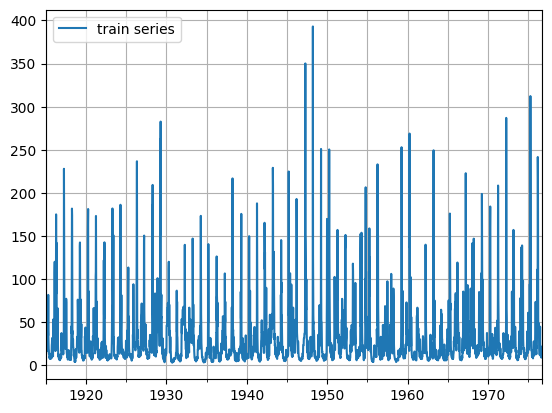

In [110]:
train_data_iter = dataset.training_dataset  # Get the training data iterator

train_data = next(iter(train_data_iter))
print("Keys in the training data: ", train_data.keys())

print("Item id: ", train_data["item_id"])
print("Start Date: ", train_data["start"])
print("Frequency: ", train_data["freq"])
print("Last 10 target values: ", train_data["target"][-10:])


train_series = to_pandas(train_data)
train_series.plot()
plt.grid(which="both")
plt.legend(["train series"], loc="upper left")
plt.show()

In [111]:
signal = train_data['target']
T_len = len(signal)
print(T_len)

3223


Energy computation progress:
0% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=33, tm_wday=0, tm_yday=103, tm_isdst=1)
5% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=33, tm_wday=0, tm_yday=103, tm_isdst=1)
9% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=33, tm_wday=0, tm_yday=103, tm_isdst=1)
14% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=33, tm_wday=0, tm_yday=103, tm_isdst=1)
19% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=33, tm_wday=0, tm_yday=103, tm_isdst=1)
23% 2 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=33, tm_wday=0, tm_yday=103, tm_isdst=1)
28% 2 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=33, tm_wday=0, tm_yday=103, tm_isdst=1)
33% 2 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=

/Users/jonghyeonlee/KMD_TS/src/KMD_lib.py:2099: RuntimeWarning: divide by zero encountered in scalar divide
  if not 1 / 1.1 < fmodes[mode_i, winL, 0] / fmodes[mode_i, 0, 0] < 1.1: #change to fixed difference maybe


5
10
0 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=46, tm_wday=0, tm_yday=103, tm_isdst=1)
1000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=48, tm_wday=0, tm_yday=103, tm_isdst=1)
2000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=50, tm_wday=0, tm_yday=103, tm_isdst=1)
3000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, tm_sec=53, tm_wday=0, tm_yday=103, tm_isdst=1)
[[ 1.          0.        ]
 [ 0.46813184  0.38673265]
 [ 0.35013195  0.        ]
 [ 0.          0.2893548 ]
 [ 0.          0.        ]
 [ 0.          0.        ]
 [ 0.04655926  0.07985134]
 [ 0.          0.        ]
 [-0.01953197 -0.01540913]
 [-0.00584271  0.        ]
 [-0.01108627 -0.07567124]
 [-0.02455392 -0.08508521]
 [-0.02863348 -0.09115169]
 [ 0.02094171 -0.0226088 ]
 [-0.05089318 -0.0063177 ]]
15
20
0 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=8, t

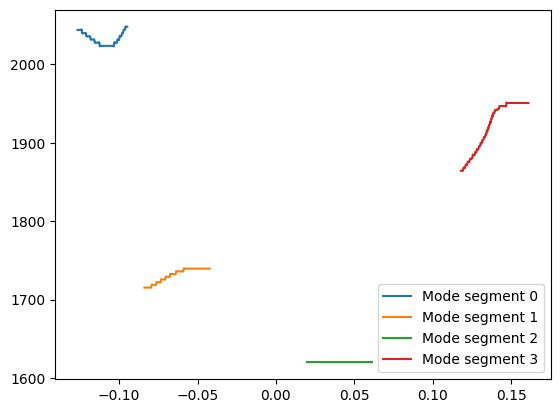

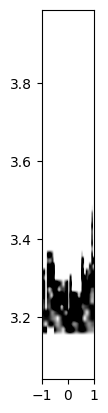

remaining_modes = [0 1 2 3]
You entered: 2
Allowed: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Membership test: True
remaining_modes = [0 1 3]
The following modes remain, select which ones to keep:


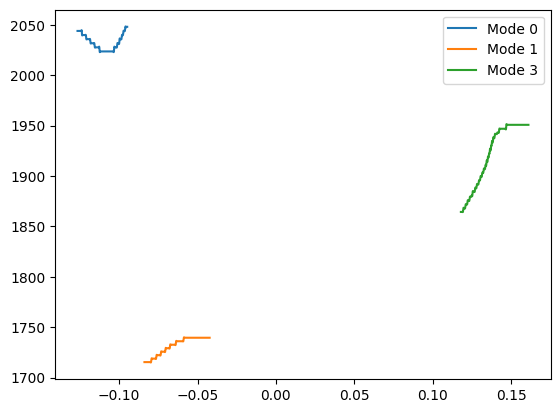

[[ 1.          0.        ]
 [ 0.58146975  0.        ]
 [-0.06373261  0.05172383]
 [ 0.37526449  0.        ]
 [ 0.15741177  0.00867408]
 [ 0.          0.        ]
 [ 0.22496572  0.        ]
 [ 0.24490571  0.        ]
 [ 0.32597233 -0.09192217]
 [ 0.24161117 -0.14320315]
 [ 0.15772586 -0.00524715]
 [ 0.35184378  0.        ]
 [ 0.39333442  0.        ]
 [ 0.4232097  -0.03431678]
 [ 0.49947284  0.        ]]
1000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=10, tm_sec=27, tm_wday=0, tm_yday=103, tm_isdst=1)
[[ 1.          0.        ]
 [ 0.0788164   0.        ]
 [ 0.25554858 -0.13075113]
 [ 0.30866779  0.1120342 ]
 [ 0.30710416 -0.27935673]
 [ 0.21967056  0.        ]
 [ 0.19317272  0.        ]
 [ 0.25648877 -0.02681194]
 [ 0.25818173 -0.0353025 ]
 [ 0.28928587  0.07059694]
 [ 0.39536352  0.        ]
 [ 0.37012248  0.        ]
 [ 0.32405144  0.        ]
 [ 0.34815755 -0.10953761]
 [ 0.31779652  0.02697501]]
3000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm

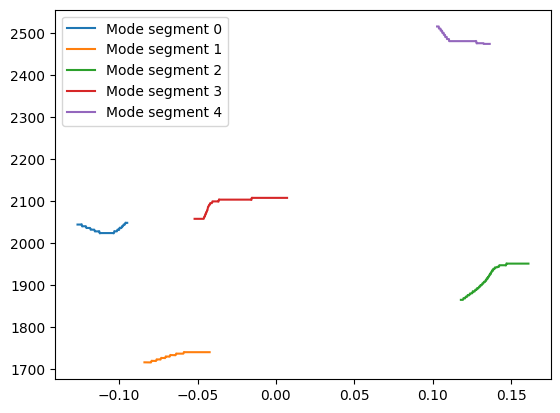

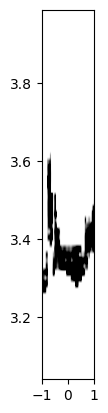

remaining_modes = [0 1 2 3 4]
You entered: 2
Allowed: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Membership test: True
remaining_modes = [0 1 3 4]
The following modes remain, select which ones to keep:


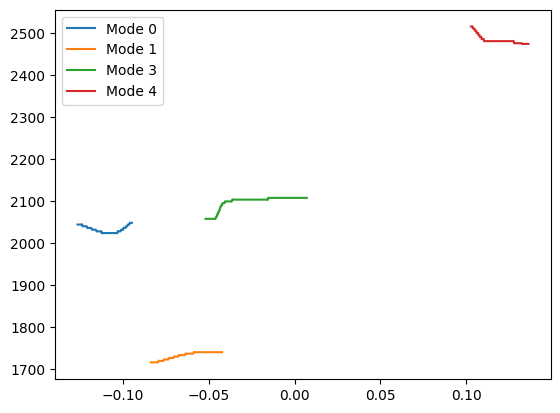

1000 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=13, tm_sec=1, tm_wday=0, tm_yday=103, tm_isdst=1)
[[ 1.          0.        ]
 [ 0.78769521  0.        ]
 [ 1.25074614  0.        ]
 [ 1.50874696  0.        ]
 [ 1.45830871  0.        ]
 [ 1.20130924  0.        ]
 [ 1.00072321  0.        ]
 [ 0.         -0.15736207]
 [ 0.         -0.19137037]
 [ 0.          0.        ]
 [ 0.          0.        ]
 [ 0.          0.        ]
 [ 0.          0.        ]
 [ 0.          0.        ]
 [ 1.5111254   0.16088536]]
[[ 1.          0.        ]
 [ 0.74453738 -0.26430407]
 [ 0.          0.        ]
 [ 0.27281562 -0.24935117]
 [ 0.19566835  0.1619169 ]
 [ 0.40799564  0.04628586]
 [ 0.10222606  0.        ]
 [ 0.50634152  0.        ]
 [ 0.         -0.06119587]
 [ 0.51725382  0.07349254]
 [ 0.51196753  0.        ]
 [ 0.34544454  0.11642341]
 [ 0.28955172  0.00749243]
 [ 0.23460333  0.        ]
 [ 0.43491145 -0.03313283]]
[[ 1.          0.        ]
 [ 0.57606976  0.        ]
 [-0.06

ValueError: could not broadcast input array from shape (309,) into shape (2662,)

In [118]:
t_mesh = np.arange(T_len, dtype=float)/10000
wave_params = ['unk',15]
alpha = 50.0

Comp_data_full, wp = KMD_lib.semimanual_maxpool_peel2(signal, wave_params, alpha, t_mesh, 0.003, 0.1, ref_fin=False)


In [117]:
Comp_data_full

array([], shape=(0, 3223, 4), dtype=float64)

In [114]:
import torch

def make_waveform_fn(coeffs):
    coeffs = torch.as_tensor(coeffs)

    def y(x):
        x = torch.as_tensor(x, dtype=coeffs.dtype, device=coeffs.device)
        out = torch.zeros_like(x)

        for k in range(coeffs.shape[0]):
            n = k + 1
            out = out + coeffs[k, 0] * torch.cos(n * x)
            if k > 0:
                out = out + coeffs[k, 1] * torch.sin(n * x)
        return out

    return y

In [115]:
def make_one_step_data(x, L=3):
    X, y = [], []
    for i in range(len(x) - L):
        X.append(x[i:i+L])
        y.append(x[i+L])
    return torch.stack(X), torch.stack(y)

def pairwise_sqdist(X1, X2):
    x1_norm = (X1**2).sum(dim=1, keepdim=True)
    x2_norm = (X2**2).sum(dim=1, keepdim=True).T
    return x1_norm + x2_norm - 2 * (X1 @ X2.T)

def gaussian_gram(X1, X2, ell):
    D2 = pairwise_sqdist(X1, X2)
    return torch.exp(-D2 / (2 * ell**2))

def median_lengthscale(X, max_points=2000):
    if len(X) > max_points:
        idx = torch.randperm(len(X))[:max_points]
        Xs = X[idx]
    else:
        Xs = X
    D2 = pairwise_sqdist(Xs, Xs)
    D = torch.sqrt(torch.clamp(D2, min=0.0))
    vals = D[torch.triu(torch.ones_like(D, dtype=torch.bool), diagonal=1)]
    vals = vals[vals > 0]
    if len(vals) == 0:
        return 1.0
    return torch.median(vals).item()

class KernelRepresenterForecaster:
    def __init__(self, L=3, ell=None, lam=1e-4, standardize=True):
        self.L = L
        self.ell = ell
        self.lam = lam
        self.standardize = standardize

        self.x_mean = None
        self.x_std = None
        self.X_train = None
        self.alpha = None

    def fit(self, x):
        X_train, y_train = make_one_step_data(x, L=self.L)

        if self.standardize:
            self.x_mean = x.mean()
            self.x_std = x.std()
            if self.x_std < 1e-8:
                self.x_std = torch.tensor(1.0, dtype=x.dtype, device=x.device)
            X_train = (X_train - self.x_mean) / self.x_std
            y_train = (y_train - self.x_mean) / self.x_std
        else:
            self.x_mean = torch.tensor(0.0, dtype=x.dtype, device=x.device)
            self.x_std = torch.tensor(1.0, dtype=x.dtype, device=x.device)

        if self.ell is None:
            self.ell = median_lengthscale(X_train)

        K = gaussian_gram(X_train, X_train, self.ell)
        n = len(X_train)
        K_reg = K + self.lam * torch.eye(n, dtype=K.dtype, device=K.device)

        self.X_train = X_train
        self.alpha = torch.linalg.solve(K_reg, y_train)

    def predict_next(self, x_window):
        xq = x_window.clone()
        if self.standardize:
            xq = (xq - self.x_mean) / self.x_std

        kq = gaussian_gram(xq.unsqueeze(0), self.X_train, self.ell).squeeze(0)
        yq = torch.dot(kq, self.alpha)

        if self.standardize:
            yq = yq * self.x_std + self.x_mean
        return yq

    def recursive_forecast(self, x_history, horizon_steps):
        history = x_history.clone()
        preds = []
        for _ in range(horizon_steps):
            x_window = history[-self.L:] 
            y_next = self.predict_next(x_window)
            preds.append(y_next)
            history = torch.cat([history, y_next.view(1)])
        return torch.stack(preds)

Keys in the validation data:  dict_keys(['item_id', 'start', 'freq', 'target'])
Item id:  T1
Start Date:  1915-01-01/1915-01-07
Frequency:  W-THU
Last 10 target values:  [21.928572  12.957143  14.900001  15.8714285 32.685715  27.442858
 20.12857   16.828571  17.27143   64.98571  ]


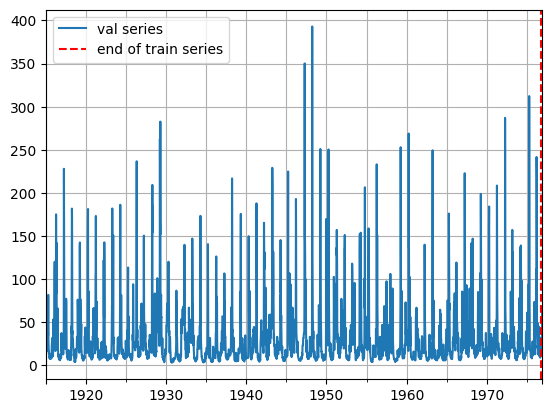

In [116]:
val_data_iter = dataset.validation_dataset

val_data = next(iter(val_data_iter))
print("Keys in the validation data: ", val_data.keys())

print("Item id: ", val_data["item_id"])
print("Start Date: ", val_data["start"])
print("Frequency: ", val_data["freq"])
print("Last 10 target values: ", val_data["target"][-10:])

val_series = to_pandas(val_data)
val_series.plot()
plt.grid(which="both")
# Add a vertical axis for where the train series ends
plt.axvline(
    x=train_series.index[-1], color="r", linestyle="--", label="End of train series"
)
plt.legend(["val series", "end of train series"], loc="upper left")
plt.show()

Keys in the test data:  dict_keys(['item_id', 'start', 'freq', 'target'])


Context Item id:  T1
Context Start Date:  1915-01-01/1915-01-07
Context Frequency:  W-THU
Context Last 10 target values:  [21.928572  12.957143  14.900001  15.8714285 32.685715  27.442858
 20.12857   16.828571  17.27143   64.98571  ]


Forecast Item id:  T1
Forecast Start Date:  1976-12-03/1976-12-09
Forecast Frequency:  W-THU
Forecast Last 10 target values:  [22.342855 18.728573 16.885714 15.400001 14.528571 14.042857 13.400001
 13.042857]


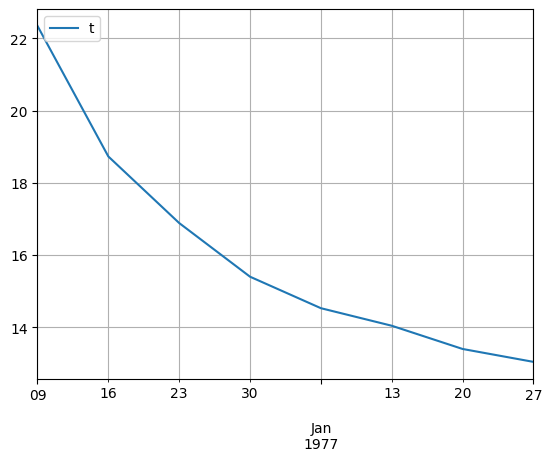

In [ ]:
# test_split_iter = dataset.test_data
# test_data = next(iter(test_split_iter))

# test_input_split_iter = dataset.test_data.input

# input = next(iter(test_input_split_iter))
# print("Keys in the test data: ", input.keys())

# print("\n\nContext Item id: ", input["item_id"])
# print("Context Start Date: ", input["start"])
# print("Context Frequency: ", input["freq"])
# print("Context Last 10 target values: ", input["target"][-10:])

# test_label_split_iter = dataset.test_data.label
# label = input = next(iter(test_label_split_iter))
# print("\n\nForecast Item id: ", label["item_id"])
# print("Forecast Start Date: ", label["start"])
# print("Forecast Frequency: ", label["freq"])
# print("Forecast Last 10 target values: ", label["target"][-10:])

# test_series = to_pandas(test_data[1])
# test_series.plot()
# plt.grid(which="both")
# plt.legend("test series", loc="upper left")
# plt.show()

In [ ]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def rmse(pred, true):
    return torch.sqrt(torch.mean((pred - true)**2))

def mae(pred, true):
    return torch.mean(torch.abs(pred - true))

v = torch.Tensor(signal)
n_train = len(v)

v_train = v[:n_train]

full_data = torch.Tensor(Comp_data_full)

a1_train = full_data[0,:n_train,0]
a2_train = full_data[1,:n_train,0]
a3_train = full_data[2,:n_train,0]
a4_train = full_data[3,:n_train,0]
a5_train = full_data[4,:n_train,0]


theta1_train = full_data[0,:n_train,1]
theta2_train = full_data[1,:n_train,1]
theta3_train = full_data[2,:n_train,1]
theta4_train = full_data[3,:n_train,1]
theta5_train = full_data[4,:n_train,1]


omega1_train = full_data[0,:n_train,2]
omega2_train = full_data[1,:n_train,2]
omega3_train = full_data[2,:n_train,2]
omega4_train = full_data[3,:n_train,2]
omega5_train = full_data[4,:n_train,2]

v_train = v[:n_train]

L_a = 1000
L_omega = 500


In [98]:
def rmse(x, y):
    return torch.sqrt(torch.mean((x - y)**2))

L = 1000
horizon_steps = len(val_data["target"])

model_v = KernelRepresenterForecaster(L=L, ell=None, lam=1e-4, standardize=True)
model_v.fit(v_train)
pred_from_v = model_v.recursive_forecast(v_train, horizon_steps)


model_a = KernelRepresenterForecaster(L=L_a, ell=None, lam=1e-4, standardize=True)


model_a.fit(a1_train)
model_a.fit(a2_train)
model_a.fit(a3_train)
model_a.fit(a4_train)
model_a.fit(a5_train)


a1_pred = model_a.recursive_forecast(a1_train, horizon_steps)
a2_pred = model_a.recursive_forecast(a2_train, horizon_steps)
a3_pred = model_a.recursive_forecast(a3_train, horizon_steps)
a4_pred = model_a.recursive_forecast(a4_train, horizon_steps)
a5_pred = model_a.recursive_forecast(a5_train, horizon_steps)


# 3) use true v1, v2 separately and sum
model_omega = KernelRepresenterForecaster(L=L_omega, ell=None, lam=1e-4, standardize=True)

model_omega.fit(omega1_train)
model_omega.fit(omega2_train)
model_omega.fit(omega3_train)
model_omega.fit(omega4_train)
model_omega.fit(omega5_train)


omega1_pred = model_omega.recursive_forecast(omega1_train, horizon_steps)
omega2_pred = model_omega.recursive_forecast(omega2_train, horizon_steps)
omega3_pred = model_omega.recursive_forecast(omega3_train, horizon_steps)
omega4_pred = model_omega.recursive_forecast(omega4_train, horizon_steps)
omega5_pred = model_omega.recursive_forecast(omega5_train, horizon_steps)


theta1_pred = torch.zeros(horizon_steps)
theta2_pred = torch.zeros(horizon_steps)
theta3_pred = torch.zeros(horizon_steps)
theta4_pred = torch.zeros(horizon_steps)
theta5_pred = torch.zeros(horizon_steps)


ss = t_mesh[1]-t_mesh[0]

theta1_pred[0] = theta1_train[-1]+ss*omega1_train[-1]
theta2_pred[0] = theta2_train[-1]+ss*omega2_train[-1]
theta3_pred[0] = theta3_train[-1]+ss*omega3_train[-1]
theta4_pred[0] = theta3_train[-1]+ss*omega4_train[-1]
theta5_pred[0] = theta3_train[-1]+ss*omega5_train[-1]


for i in range(1,horizon_steps):
    theta1_pred[i] = theta1_pred[i-1]+ss*omega1_pred[i-1]
    theta2_pred[i] = theta2_pred[i-1]+ss*omega2_pred[i-1]
    theta3_pred[i] = theta3_pred[i-1]+ss*omega3_pred[i-1]
    theta4_pred[i] = theta4_pred[i-1]+ss*omega4_pred[i-1]
    theta5_pred[i] = theta5_pred[i-1]+ss*omega5_pred[i-1]




In [104]:
y1 = make_waveform_fn(wp.f[0])
y2 = make_waveform_fn(wp.f[1])
y3 = make_waveform_fn(wp.f[2])
y4 = make_waveform_fn(wp.f[3])
y5 = make_waveform_fn(wp.f[4])


osc_1 = y1(theta1_pred)
osc_2 = y2(theta2_pred)
osc_3 = y3(theta3_pred)
osc_4 = y4(theta4_pred)
osc_5 = y5(theta5_pred)

v_test = torch.Tensor(val_data["target"])


pred_from_KMD = a1_pred*osc_1+a2_pred*osc_2+a3_pred*osc_3+a4_pred*osc_4+a5_pred*osc_5

h = horizon_steps

err_v = torch.linalg.norm(pred_from_v[:h] - v_test[:h]) / torch.linalg.norm(v_test[:h])
err_kmd = torch.linalg.norm(pred_from_KMD[:h] - v_test[:h]) / torch.linalg.norm(v_test[:h])

print("Relative error: using v directly, scored vs future v =", err_v.item())
print(r"Relative error: using predicted $a_i,\omega_i$, scored vs future v =", err_kmd.item())

Relative error: using v directly, scored vs future v = 1.1079548597335815
Relative error: using predicted $a_i,\omega_i$, scored vs future v = 1.0091922015945962


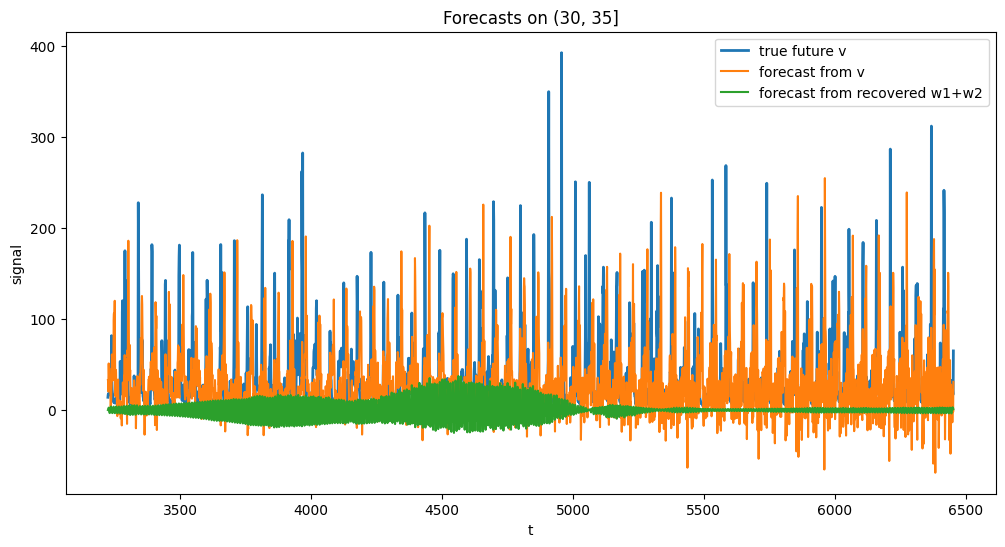

In [105]:
t_future = np.arange(n_train,n_train+horizon_steps)
plt.figure(figsize=(12, 6))
plt.plot(t_future[:h], v_test[:h], label="true future v", linewidth=2)
plt.plot(t_future[:h], pred_from_v[:h], label="forecast from v")
plt.plot(t_future[:h], pred_from_KMD[:h], label="forecast from recovered w1+w2")
plt.legend()
plt.xlabel("t")
plt.ylabel("signal")
plt.title("Forecasts on (30, 35]")
plt.show()

Energy computation progress:
0% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=0, tm_sec=52, tm_wday=0, tm_yday=103, tm_isdst=1)
5% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=0, tm_sec=52, tm_wday=0, tm_yday=103, tm_isdst=1)
9% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=0, tm_sec=52, tm_wday=0, tm_yday=103, tm_isdst=1)
14% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=0, tm_sec=52, tm_wday=0, tm_yday=103, tm_isdst=1)
19% 4 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=0, tm_sec=52, tm_wday=0, tm_yday=103, tm_isdst=1)
23% 2 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=0, tm_sec=52, tm_wday=0, tm_yday=103, tm_isdst=1)
28% 2 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=0, tm_sec=52, tm_wday=0, tm_yday=103, tm_isdst=1)
33% 2 time.struct_time(tm_year=2026, tm_mon=4, tm_mday=13, tm_hour=19, tm_min=

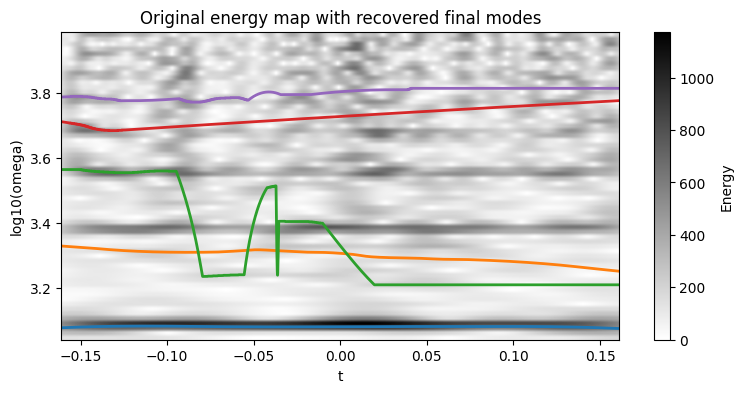

In [107]:
om_mesh = KMD_lib.make_omega_mesh(t_mesh, alpha)

E_original = KMD_lib.compute_E_fast(
    t_mesh,
    om_mesh,
    wp,
    signal,
    np.zeros((0, len(t_mesh), 4)),
    np.zeros((0, len(t_mesh), 2, 2)),
    0,
    alpha
)

plt.figure(figsize=(9, 4))
plt.imshow(
    E_original,
    cmap="gray_r",
    origin="lower",
    aspect="auto",
    extent=[t_mesh[0], t_mesh[-1], np.log10(om_mesh[0]), np.log10(om_mesh[-1])]
)

for mode_i in range(Comp_data_full.shape[0]):
    omega_i = Comp_data_full[mode_i, :, 2]
    nz = np.nonzero(omega_i)[0]
    if len(nz) > 0:
        plt.plot(t_mesh[nz], np.log10(omega_i[nz]), linewidth=2)

plt.colorbar(label="Energy")
plt.xlabel("t")
plt.ylabel("log10(omega)")
plt.title("Original energy map with recovered final modes")
plt.show()